# Toxic Comment Classification with BERT and Twitter-RoBERTa

**Team:** Abhishek Dadi (261100660029) · Rahul Kemburu (261100660005) · Shashwath Naren PV (261100660031)

We fine-tune two language models to classify comments as **toxic** or **not toxic**, then compare them using standard classification metrics.

| Model | Pre-trained on | Worked on by |
|---|---|---|
| BERT-base (baseline) | Books and Wikipedia | Rahul, Shashwath |
| Twitter-RoBERTa (improved) | Web text + 154 million tweets | Abhishek |

**Steps:** 1. Setup → 2. Data → 3. Training → 4. Metrics → 5. Try your own comments

Run on Google Colab with a **T4 GPU**. Data, models and results are saved to Google Drive.

## 1. Setup

In [1]:
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')

GPU 0: Tesla T4 (UUID: GPU-31aee821-a87d-bc4f-0d37-5077aa041598)
Mounted at /content/drive


In [2]:
import glob, inspect, json, math, os, random, re, shutil, time
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

### Settings
Both models use exactly the same settings, so the comparison is fair.
Keep `retrain=False`: if trained models already exist on Drive, they are loaded instead of trained again.

In [3]:
args = SimpleNamespace(
    out_dir="/content/drive/MyDrive/aps_toxicity",
    baseline="bert-base-uncased",
    improved="cardiffnlp/twitter-roberta-base-2022-154m",
    train_size=100_000, train_pos_frac=0.25,   # 100,000 training comments, 25% toxic
    val_size=15_000, test_size=20_000,
    epochs=2, batch_size=32, lr=2e-5, max_len=128,
    seed=42,
    retrain=False,
)
OUT = args.out_dir
DATA_DIR, MODEL_ROOT, CKPT_ROOT = f"{OUT}/data", f"{OUT}/models", f"{OUT}/checkpoints"
for d in (OUT, DATA_DIR, MODEL_ROOT, CKPT_ROOT):
    os.makedirs(d, exist_ok=True)
MODEL_NAMES = {"baseline": "BERT", "improved": "Twitter-RoBERTa"}

### Helper functions
`set_all_seeds` makes results reproducible. `clean` replaces web links with `http` and usernames with `@user`.

In [4]:
def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def clean(text):
    t = str(text)
    t = re.sub(r"https?://\S+|www\.\S+", "http", t)
    t = re.sub(r"@\w+", "@user", t)
    return re.sub(r"\s+", " ", t).strip()


set_all_seeds(args.seed)
print(clean('Check this https://t.co/abc  @john_99   lol'))

Check this http @user lol


## 2. Data

**Civil Comments** (Jigsaw / Google): about 2 million real comments from news websites, each rated by several people.
A comment is labelled **toxic (1)** if at least half of the raters called it toxic, otherwise **not toxic (0)**.

| Split | Size | Toxic share | Used for |
|---|---|---|---|
| Train | 100,000 | 25% (toxic comments over-represented) | Teaching the models |
| Validation | 15,000 | about 8% (real rate) | Choosing the decision threshold |
| Test | 20,000 | about 8% (real rate) | Final evaluation, used only once |

If the samples are already saved on Drive, they are loaded instead of downloaded again.

In [5]:
def prepare_data(args, data_dir):
    paths = {s: f"{data_dir}/{s}.csv" for s in ("train", "val", "test")}
    if all(os.path.exists(p) for p in paths.values()):
        print("Loading saved samples from Drive")
        return {s: pd.read_csv(p, keep_default_na=False) for s, p in paths.items()}

    from datasets import load_dataset
    print("Downloading Civil Comments from Hugging Face ...")
    cc = load_dataset("google/civil_comments")

    def population(split):
        d = cc[split]
        d = d.remove_columns([c for c in d.column_names if c not in ("text", "toxicity")])
        df = d.to_pandas().reset_index().rename(columns={"index": "orig_idx"})
        df["label"] = (df["toxicity"] >= 0.5).astype(int)
        df["text"] = df["text"].map(clean)
        return df[df["text"].str.len() > 0]

    tr_pop, va_pop, te_pop = population("train"), population("validation"), population("test")
    n_pos = int(round(args.train_size * args.train_pos_frac))
    train = pd.concat([
        tr_pop[tr_pop.label == 1].sample(n=n_pos, random_state=args.seed),
        tr_pop[tr_pop.label == 0].sample(n=args.train_size - n_pos, random_state=args.seed),
    ]).sample(frac=1, random_state=args.seed)
    val = va_pop.sample(n=args.val_size, random_state=args.seed)
    frac = args.test_size / len(te_pop)
    test = (te_pop.groupby("label", group_keys=False)
                  .sample(frac=frac, random_state=args.seed)
                  .sample(frac=1, random_state=args.seed))
    for s, df in {"train": train, "val": val, "test": test}.items():
        df[["orig_idx", "text", "toxicity", "label"]].to_csv(paths[s], index=False)
    return {s: pd.read_csv(p, keep_default_na=False) for s, p in paths.items()}


data = prepare_data(args, DATA_DIR)
pd.DataFrame({s: {"comments": len(df), "toxic": int(df.label.sum()), "toxic share": f"{df.label.mean():.2%}"}
              for s, df in data.items()}).T

Loading saved samples from Drive


,comments,toxic,toxic share
train,100000,25000,25.00%
val,15000,1173,7.82%
test,20000,1598,7.99%


In [6]:
# A few examples from the test set
data["test"][["text", "label"]].sample(8, random_state=1)

,text,label
11456,The gift that keeps giving/ taking .,0
16528,it should be any adults choice. many people re...,0
3253,why doesn`t Alan Hutchinson do the right thing...,0
18614,WalMart may sell a wider range but they have a...,0
1544,Look for a sudden rise in server openings at l...,0
12568,"Rather than the routine monotones, some actual...",0
15497,Does he understand in Canada cash is king?,0
13987,"Here's a liar, lying to cover for the liars sh...",1


## 3. Training and prediction

- `train_or_load`: fine-tunes a pre-trained model on the training comments (or loads it from Drive if already trained).
- `predict_proba`: gives the probability that each comment is toxic.
- `tune_threshold`: chooses the probability cut-off that gives the best F1 on the **validation** set.

In [7]:
def train_or_load(model_name, train_df, args, model_root, ckpt_root):
    import torch
    from datasets import Dataset
    from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                              DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)

    run = model_name.split("/")[-1]
    model_dir, ckpt_dir = f"{model_root}/{run}", f"{ckpt_root}/{run}"
    if os.path.exists(f"{model_dir}/config.json") and not args.retrain:
        print(f"[train] Saved model found for {run}, skipping training.")
        return model_dir

    set_seed(args.seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    ds = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True))
    ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=args.max_len),
                batched=True, remove_columns=["text"])

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=2, id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1})

    total_steps = int(math.ceil(len(ds) / args.batch_size) * args.epochs)
    wanted = dict(
        output_dir=ckpt_dir, num_train_epochs=args.epochs,
        per_device_train_batch_size=args.batch_size, learning_rate=args.lr,
        weight_decay=0.01, warmup_steps=int(0.06 * total_steps), lr_scheduler_type="linear",
        fp16=torch.cuda.is_available(), eval_strategy="no",
        save_strategy="steps", save_steps=1000, save_total_limit=1,
        logging_steps=200, report_to="none", seed=args.seed, data_seed=args.seed,
        dataloader_num_workers=2, group_by_length=True)
    supported = set(inspect.signature(TrainingArguments.__init__).parameters)
    targs = TrainingArguments(**{k: v for k, v in wanted.items() if k in supported})

    trainer = Trainer(model=model, args=targs, train_dataset=ds,
                      data_collator=DataCollatorWithPadding(tok))
    ckpts = sorted(glob.glob(f"{ckpt_dir}/checkpoint-*"), key=lambda x: int(x.split("-")[-1]))
    print(f"[train] {run}: {len(ds):,} examples, {total_steps} steps, resume={ckpts[-1] if ckpts else None}")
    t0 = time.time()
    trainer.train(resume_from_checkpoint=ckpts[-1] if ckpts else None)
    print(f"[train] {run} finished in {(time.time() - t0) / 60:.1f} min")

    trainer.save_model(model_dir)
    tok.save_pretrained(model_dir)
    shutil.rmtree(ckpt_dir, ignore_errors=True)   # free Drive space
    del trainer, model
    torch.cuda.empty_cache()
    return model_dir


def predict_proba(model_dir, texts, args, batch_size=256):
    """Returns P(toxic) for every text."""
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device).eval()
    if device == "cuda":
        model.half()
    texts = [str(t) for t in texts]
    order = np.argsort([len(t) for t in texts])   # length-sorted batches = less padding = faster
    probs = np.empty(len(texts))
    with torch.inference_mode():
        for i in range(0, len(texts), batch_size):
            idx = order[i:i + batch_size]
            enc = tok([texts[j] for j in idx], truncation=True, max_length=args.max_len,
                      padding=True, return_tensors="pt").to(device)
            probs[idx] = torch.softmax(model(**enc).logits.float(), dim=-1)[:, 1].cpu().numpy()
    del model
    if device == "cuda":
        torch.cuda.empty_cache()
    return probs


def tune_threshold(y, p):
    """Pick the decision threshold that maximises F1 on the validation sample."""
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = [f1_score(y, p >= t, zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))])

In [8]:
PRED_PATH, THR_PATH = f"{OUT}/predictions_test.csv", f"{OUT}/thresholds.json"
pred = data["test"][["orig_idx", "label"]].copy()
thr = {}
model_dirs = {}

def run_model(role, name):
    set_all_seeds(args.seed)
    model_dirs[role] = train_or_load(name, data["train"], args, MODEL_ROOT, CKPT_ROOT)
    val_p = predict_proba(model_dirs[role], data["val"]["text"].tolist(), args)
    pred[f"p_{role}"] = predict_proba(model_dirs[role], data["test"]["text"].tolist(), args)
    thr[role] = tune_threshold(data["val"]["label"].values, val_p)
    print(f"{MODEL_NAMES[role]}: threshold = {thr[role]}")

### BERT (baseline)

In [9]:
run_model("baseline", args.baseline)

[train] Saved model found for bert-base-uncased, skipping training.


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERT: threshold = 0.84


### Twitter-RoBERTa (improved)

In [10]:
run_model("improved", args.improved)

[train] Saved model found for twitter-roberta-base-2022-154m, skipping training.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Twitter-RoBERTa: threshold = 0.86


In [11]:
pred.to_csv(PRED_PATH, index=False)
json.dump(thr, open(THR_PATH, "w"), indent=2)
pred.head()

,orig_idx,label,p_baseline,p_improved
0,60603,0,0.002975,0.001142
1,30828,0,0.000488,0.000587
2,88644,0,0.266811,0.059428
3,43997,0,0.000449,0.000712
4,42888,0,0.000601,0.000579


**Already ran the cells above before?** You can skip them and run this cell instead to load the saved predictions.

In [12]:
pred = pd.read_csv(PRED_PATH)
thr = json.load(open(THR_PATH))
model_dirs = {"baseline": f"{MODEL_ROOT}/bert-base-uncased", "improved": f"{MODEL_ROOT}/twitter-roberta-base-2022-154m"}
print("Loaded", len(pred), "test predictions. Thresholds:", thr)

Loaded 20000 test predictions. Thresholds: {'baseline': 0.84, 'improved': 0.86}


## 4. Metrics on the test set (20,000 comments)

| Metric | Question it answers |
|---|---|
| Accuracy | What share of all comments did the model classify correctly? |
| Precision | Of the comments it flagged as toxic, how many really were toxic? |
| Recall | Of all the toxic comments, how many did it catch? |
| F1 score | Balance of precision and recall (our main metric, because only about 8% of comments are toxic) |
| ROC-AUC | How well does the model rank toxic comments above harmless ones? (1.0 = perfect, 0.5 = random) |

In [13]:
y = pred["label"].values
yhat = {r: (pred[f"p_{r}"].values >= thr[r]).astype(int) for r in MODEL_NAMES}

metrics = pd.DataFrame({
    MODEL_NAMES[r]: {
        "Accuracy": accuracy_score(y, yhat[r]),
        "Precision": precision_score(y, yhat[r]),
        "Recall": recall_score(y, yhat[r]),
        "F1 score": f1_score(y, yhat[r]),
        "ROC-AUC": roc_auc_score(y, pred[f"p_{r}"]),
    } for r in MODEL_NAMES})
metrics["Difference (RoBERTa − BERT)"] = metrics["Twitter-RoBERTa"] - metrics["BERT"]
metrics.round(4)

,BERT,Twitter-RoBERTa,Difference (RoBERTa − BERT)
Accuracy,0.9502,0.9528,0.0026
Precision,0.6930,0.7217,0.0287
Recall,0.6752,0.6652,-0.0100
F1 score,0.6840,0.6923,0.0083
ROC-AUC,0.9617,0.9650,0.0032


### Confusion matrices
Rows are the true labels, columns are the model's predictions.

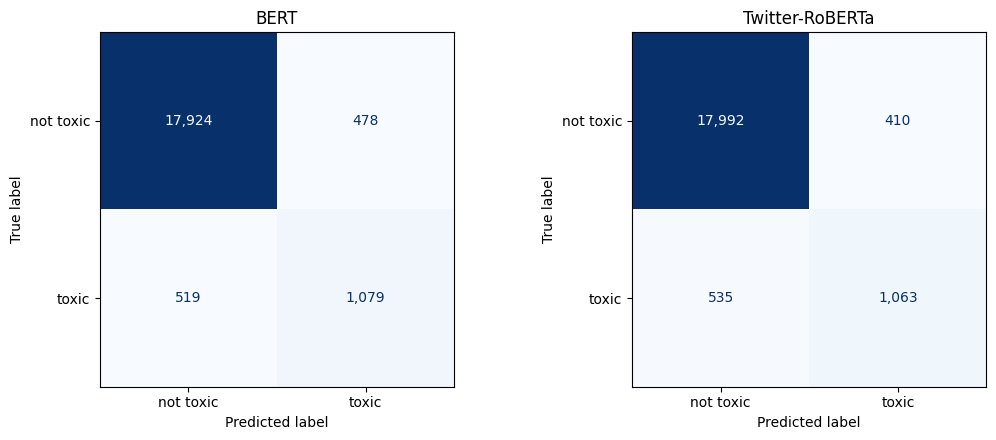

BERT             correct toxic: 1,079 | false alarms: 478 | missed toxic: 519 | correct harmless: 17,924
Twitter-RoBERTa  correct toxic: 1,063 | false alarms: 410 | missed toxic: 535 | correct harmless: 17,992


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, r in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay(confusion_matrix(y, yhat[r]), display_labels=["not toxic", "toxic"]).plot(
        ax=ax, cmap="Blues", values_format=",", colorbar=False)
    ax.set_title(MODEL_NAMES[r])
plt.tight_layout(); plt.show()

for r in MODEL_NAMES:
    tn, fp, fn, tp = confusion_matrix(y, yhat[r]).ravel()
    print(f"{MODEL_NAMES[r]:16s} correct toxic: {tp:,} | false alarms: {fp:,} | missed toxic: {fn:,} | correct harmless: {tn:,}")

### ROC curves

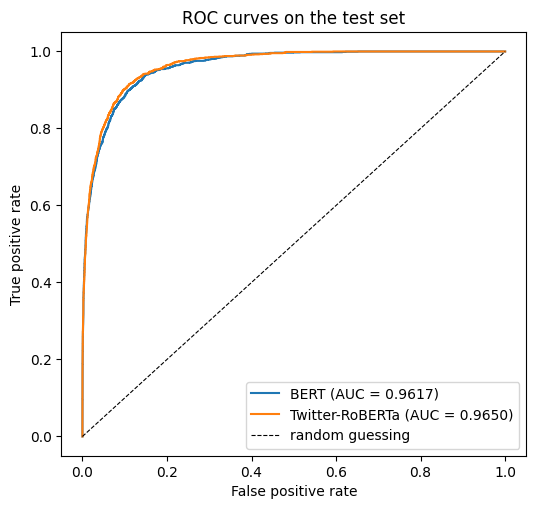

In [15]:
plt.figure(figsize=(6, 5.5))
for r in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y, pred[f"p_{r}"])
    plt.plot(fpr, tpr, label=f"{MODEL_NAMES[r]} (AUC = {roc_auc_score(y, pred[f'p_{r}']):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random guessing")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right"); plt.show()

### Full classification reports

In [16]:
for r in MODEL_NAMES:
    print(f"===== {MODEL_NAMES[r]} =====")
    print(classification_report(y, yhat[r], target_names=["not toxic", "toxic"], digits=4))

===== BERT =====
              precision    recall  f1-score   support

   not toxic     0.9719    0.9740    0.9729     18402
       toxic     0.6930    0.6752    0.6840      1598

    accuracy                         0.9502     20000
   macro avg     0.8324    0.8246    0.8285     20000
weighted avg     0.9496    0.9502    0.9499     20000

===== Twitter-RoBERTa =====
              precision    recall  f1-score   support

   not toxic     0.9711    0.9777    0.9744     18402
       toxic     0.7217    0.6652    0.6923      1598

    accuracy                         0.9527     20000
   macro avg     0.8464    0.8215    0.8333     20000
weighted avg     0.9512    0.9527    0.9519     20000



### Where the two models disagree
Examples from the test set where one model was right and the other was wrong.

In [17]:
view = data["test"][["orig_idx", "text"]].merge(pred, on="orig_idx")
for r in MODEL_NAMES:
    view[MODEL_NAMES[r]] = (view[f"p_{r}"] >= thr[r]).map({True: "toxic", False: "not toxic"})
view["truth"] = view["label"].map({1: "toxic", 0: "not toxic"})
disagree = view[view["BERT"] != view["Twitter-RoBERTa"]]
print(f"The models disagree on {len(disagree):,} of {len(view):,} comments.")
pd.set_option("display.max_colwidth", 120)
disagree[["text", "truth", "BERT", "Twitter-RoBERTa"]].sample(10, random_state=0)

The models disagree on 438 of 20,000 comments.


,text,truth,BERT,Twitter-RoBERTa
9618,"He questioned his ""loyalty""? For what? A gang? A business idea? What for? If there's a gang, bust them all. We shoul...",toxic,toxic,not toxic
16136,"one thing for sure, is that the shoulder mounted ""body cams"" suck. Way too much body movement at the shoulder. body ...",toxic,toxic,not toxic
11309,Another Morlino Monster.,not toxic,toxic,not toxic
14361,"When Denver got shut out, the offense still didn't get an F. These grades are just silly. The offense scored zero po...",not toxic,toxic,not toxic
2257,The squealing from loyal Liberals is always rewarded with a heaping dose of public slop.,toxic,not toxic,toxic
276,The Globe is the last bastion of civility and seeming sillier all the time.,not toxic,not toxic,toxic
7736,Just curious. How's the recovery efforts going in Houston and Florida after those horrific storms? Also any humanita...,not toxic,toxic,not toxic
12469,"Trump will be a goldmine for satirists, especially with that hair. Bannon should be portrayed scabs and all.",not toxic,toxic,not toxic
12237,"IRT - Bill Miller. Oh Bill, Bill, Bill, you must be new here. There has NEVER been a yes or no vote on rail on Oahu....",not toxic,toxic,not toxic
14360,"I disagree; Handy is an pompous arrogant PC liberal who as not doing the work of the people, he was pulling a dirty ...",toxic,not toxic,toxic


## 5. Try your own comments
Type any comments in the list and both models classify them.

In [18]:
my_comments = [
    "Congrats on the launch, the new feature looks great!",
    "This take is dumb, honestly.",
    "You are a worthless idiot and nobody cares what you think.",
    "lmao this ref is trash, worst call of the season",
]
out = pd.DataFrame({"comment": my_comments})
for r in MODEL_NAMES:
    p = predict_proba(model_dirs[r], my_comments, args)
    out[f"{MODEL_NAMES[r]} P(toxic)"] = [f"{x:.1%}" for x in p]
    out[f"{MODEL_NAMES[r]} verdict"] = ["toxic" if x >= thr[r] else "not toxic" for x in p]
out

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,comment,BERT P(toxic),BERT verdict,Twitter-RoBERTa P(toxic),Twitter-RoBERTa verdict
0,"Congrats on the launch, the new feature looks great!",0.1%,not toxic,0.1%,not toxic
1,"This take is dumb, honestly.",99.6%,toxic,99.7%,toxic
2,You are a worthless idiot and nobody cares what you think.,99.5%,toxic,99.8%,toxic
3,"lmao this ref is trash, worst call of the season",99.6%,toxic,99.7%,toxic


## Summary

Both models classify toxic comments well, with about 95% accuracy and ROC-AUC above 0.96.
Twitter-RoBERTa scores slightly higher on most metrics. It is more cautious: it raises fewer false alarms but misses a few more toxic comments than BERT.
The full statistical analysis of whether this difference is reliable is in `toxicity_stats.py` and our report.